In [3]:
!pip install nbformat



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Adım 1 Tamamlandı: Yollar ve Kurallar Belirlendi.
Adım 2 Tamamlandı: Jeneratör Kuralları Başarıyla Hazırlandı.
Found 4173 images belonging to 2 classes.
Found 1059 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Adım 3 Tamamlandı: Veri akış kanalları başarıyla bağlandı.
Sınıf İndeksleri (Etiketler):
{'NORMAL': 0, 'PNEUMONIA': 1}
Resim Paketinin Boyutu (Shape) : (32, 224, 224, 3)
Etiket Paketinin Boyutu (Shape): (32,)
En Düşük Piksel Değeri         : 0.0
En Yüksek Piksel Değeri        : 1.0


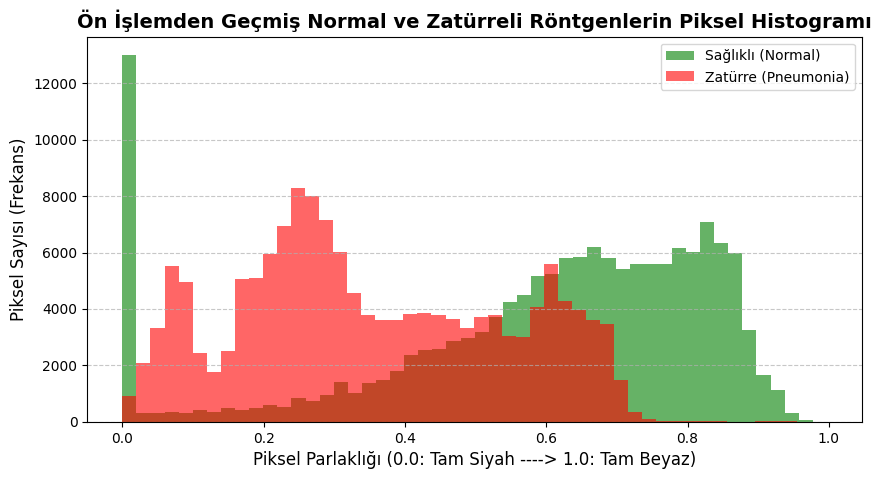

In [4]:
%run 02_veri_onisleme.ipynb

In [5]:
# Gerekli Keras katmanlarını ve model yapısını içeri aktarıyoruz
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Sequential: Katmanları arka arkaya, sırayla (bir tünel gibi) dizeceğimizi belirtir.
model = Sequential()

# =====================================================================
# BÖLÜM 1: ÖZELLİK ÇIKARIMI (GÖZLER - CONVOLUTION & POOLING)
# =====================================================================

# --- 1. BLOK: Yüzeysel Özellikler (Düz çizgiler, kenarlar) ---
# Giriş: Hastaneden gelen tek bir orijinal resim (224x224 boyutunda, 3 renk kanallı).
# İşlem: 32 farklı 3x3 büyüteç, resmi tarayarak yatay/dikey çizgi haritaları çıkarır.
model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', input_shape=(224, 224, 3)))
# Küçültme: 2x2'lik çerçevelerle sadece en parlak/belirgin pikselleri alıp resmi yarı yarıya küçültür.
# Çıkış: Orijinal resim çöpe gider. Elimizde 112x112 boyutunda, 32 katmanlı (desteli) bir özellik haritası kalır.
model.add(MaxPooling2D(pool_size=(2, 2)))


# --- 2. BLOK: Orta Düzey Özellikler (Şekiller, kemik ve doku kıvrımları) ---
# İşlem: Buradaki 64 büyütecin her biri 3 boyutludur (3x3x32). Yani 1. bloktan gelen 32 katmanlı
# desteye zımba gibi yukarıdan aşağıya basar, hepsini harmanlayıp ezerek yepyeni tek bir resim çıkarır.
# Bu zımba işlemi 64 farklı büyüteçle yapıldığı için 64 yeni harita oluşur.
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
# Küçültme: 112x112'lik haritaları tekrar yarı yarıya özetler.
# Çıkış: Elimizde 56x56 boyutunda, 64 katmanlı (desteli) daha soyut bir özellik haritası oluşur.
model.add(MaxPooling2D(pool_size=(2, 2)))


# --- 3. BLOK: Derin Analiz (Zatürreye özgü beyazlıklar, bulutsu lekeler) ---
# İşlem: 128 farklı 3 boyutlu büyüteç (3x3x64), 64'lü desteye basarak hastalık lekelerini parlatır.
model.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
# Küçültme: 56x56'lık haritaları tekrar özetler.
# Çıkış: Elimizde 28x28 boyutunda, 128 katmanlı, sadece hastalıklı bölgelerin parladığı haritalar kalır.
model.add(MaxPooling2D(pool_size=(2, 2)))


# --- 4. BLOK: En İnce Detaylar (Son Damıtma) ---
# İşlem: 128 filtre (3x3x128), hastalık haritalarının üzerinden son kez geçip en soyut, en kritik izleri damıtır.
model.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
# Küçültme: 28x28'lik haritaları son kez yarı yarıya küçültür.
# Çıkış (Karar Merkezine Gidecek Veri): Artık elimizde resim değil; 14x14 boyutunda, 128 katmanlı, 
# "Hastalık lekeleri tam olarak nerede ve ne yoğunlukta?" bilgisini taşıyan saf bir matematiksel rapor var.
model.add(MaxPooling2D(pool_size=(2, 2)))

c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Bölüm 1: Model Oluşturma (Model Construction) Adımları ve Mimari Tercihler

Veri ön işleme aşamasından geçen standartlaştırılmış (224x224x3 boyutlarındaki) röntgen görüntülerini analiz etmek, hastalık belirtilerini otonom olarak saptamak ve yüksek doğrulukla sınıflandırmak amacıyla projeye özgü bir Evrişimli Sinir Ağı (CNN) mimarisi tasarlanmıştır. Bu mimari, "Özellik Çıkarımı" ve "Sınıflandırma" olmak üzere iki temel veri işleme fazından oluşmaktadır. Gerçekleştirilen yapısal katman tercihleri ve bunların arka plandaki mühendislik gerekçeleri aşağıda detaylandırılmıştır:

 Özellik Çıkarımı (Feature Extraction - Convolution & Pooling) Aşaması
Röntgen görüntülerindeki anatomik yapıların ve patolojik anomalilerin tespit edilebilmesi için 4 ardışık evrişim (Convolution) ve havuzlama (Pooling) bloğu kurgulanmıştır.

Evrişim (Conv2D) Katmanları ve Filtre Hiyerarşisi: Ağa giriş yapan görüntüler ilk aşamada 32 adet (3x3 boyutlu) filtre (kernel) ile taranarak akciğer sınırları ve kaburga kemikleri gibi temel, yüzeysel morfolojik hatlar tespit edilmiştir. Ağ derinleştikçe filtre sayısı kademeli olarak artırılmış (64, 128 ve 128) ve modelin yüzeysel çizgilerden ziyade, zatürreye (Pneumonia) özgü düzensiz beyaz sıvı birikintilerini (infiltrasyon/opaklık) ve karmaşık doku bozulmalarını saptaması hedeflenmiştir. Tüm evrişim işlemlerinde, ağa doğrusal olmayan (non-linear) bir hesaplama yeteneği kazandırmak ve negatif piksel değerlerini sıfırlayarak ağın yalnızca pozitif (anlamlı) sinyallere odaklanmasını sağlamak amacıyla ReLU (Rectified Linear Unit) aktivasyon fonksiyonu kullanılmıştır.

Havuzlama (MaxPooling2D) Katmanları: Her evrişim bloğunun ardına 2x2 boyutlu maksimum havuzlama (Max Pooling) katmanı eklenmiştir. Bu işlem, her 4 piksellik penceredeki en yüksek değerli (en baskın) özelliği alarak görüntülerin uzamsal (spatial) boyutlarını (224x224'ten kademeli olarak 12x12'ye kadar) küçültmüştür. Bu stratejik boyut indirgeme işlemi sayesinde; hesaplama maliyeti (RAM ve işlemci yükü) minimize edilmiş, modelin uzamsal kaymalara karşı direnci artırılmış ve resimdeki gereksiz piksellerin ezberlenmesinin (overfitting) önüne geçilerek en kritik patolojik izler damıtılmıştır.

In [6]:
# =====================================================================
# BÖLÜM 2: KARAR MERKEZİ (BEYİN - FLATTEN & DENSE)
# =====================================================================

# --- 5. BLOK: Düzleştirme (Flatten) ---
# Gözlerden gelen 14x14x128 boyutundaki 3 boyutlu küp şeklindeki özellik haritasını alıp,
# karar nöronlarının okuyabilmesi için upuzun tek boyutlu (1D) bir sayı şeridine dönüştürüyoruz.
model.add(Flatten())


# --- 6. BLOK: Gizli Katman (Mantık Nöronları) ---
# Düzleştirilmiş veriyi okuyup, aralarındaki bağlantılardan mantıksal "Zatürre Teşhisi"
# çıkarımı yapacak olan 256 adet yapay beyin hücresi (nöron) ekliyoruz.
model.add(Dense(units=256, activation='relu'))


# --- 7. BLOK: Ezberi Bozma (Dropout) ---
# Modelin eğitim resimlerini (gölgeleri, yazıları) körü körüne ezberlemesini (Overfitting) engellemek için,
# her eğitim adımında bu 256 nöronun yarısını (%50) rastgele uyutuyoruz/kapatıyoruz.
# Böylece model tek bir bölgeye saplanıp kalmak yerine resmin bütününe odaklanmak zorunda kalıyor.
model.add(Dropout(rate=0.5))


# --- 8. BLOK: Çıkış Katmanı (Son Karar Hakemi) ---
# İki sınıfımız (Zatürre=1, Sağlıklı=0) olduğu için sonuca sadece 1 adet hakem nöron koyuyoruz.
# 'sigmoid' aktivasyonu sayesinde bu nöron bize 0.0 ile 1.0 arasında matematiksel bir ihtimal veriyor.
# Örn: Çıktı 0.85 ise model %85 ihtimalle "Zatürre" teşhisi koyar.
model.add(Dense(units=1, activation='sigmoid'))


# Tüm kurduğumuz modelin yapısal özetini ve eğitilecek parametre sayılarını ekrana yazdırıyoruz:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,959,937 (18.92 MB)

 Trainable params: 4,959,937 (18.92 MB)

 Non-trainable params: 0 (0.00 B)

Bölüm 2: Karar Merkezi ve Sınıflandırma (Classification - Flatten & Dense) Aşaması
Evrişim katmanları tarafından çıkarılan çok boyutlu ve soyut özellik haritalarının, matematiksel ve mantıksal bir teşhis kararına dönüştürüldüğü nihai aşamadır.

Vektörizasyon (Flatten Katmanı): Özellik çıkarımı fazının sonunda elde edilen 3 boyutlu özellik küpleri, yapay sinir ağının (Dense) işleyebileceği veri yapısına uyarlanmak zorundadır. Bu doğrultuda Flatten katmanı kullanılarak, 3 boyutlu matrisler ezilmiş ve yaklaşık 18.000 elemanlı tek boyutlu (1D) kesintisiz bir sayı vektörüne dönüştürülmüştür.

Derin Bağlantılar ve Mantıksal Çıkarım (Dense Katmanı): Vektör haline getirilen özellikler, aralarındaki karmaşık ilişkileri ve çapraz bağlantıları kurmak üzere 256 nörondan (yapay beyin hücresi) oluşan tam bağlı (Fully Connected/Dense) bir gizli katmana aktarılmıştır. Bu katman, farklı bölgelerden gelen anomali sinyallerini birleştirerek "Zatürre" teşhisinin arka plandaki tıbbi mantığını matematiksel olarak kurgulamaktadır.

Regülarizasyon ve Ezberi Bozma (Dropout Katmanı): Yapay sinir ağlarının eğitim verilerindeki hastane logoları, tıbbi cihaz kabloları veya spesifik görüntü açıları gibi tesadüfi detayları ezberleme eğilimi bulunmaktadır. Bu aşırı öğrenme (Overfitting) problemini kesin olarak çözmek amacıyla modele %50 oranında (0.5) Dropout (seyreltme) uygulanmıştır. Bu yöntem, her eğitim iterasyonunda 256 nöronun yarısını rastgele inaktif duruma getirerek, ağın tek bir piksel grubuna bağımlı kalmasını engellemiş ve modelin resmi bir bütün olarak analiz edip genelleme yapabilmesini zorunlu kılmıştır.

Nihai Karar (Output Katmanı): Çözümlenmesi hedeflenen problem (Zatürre ve Normal) ikili (binary) bir sınıflandırma problemi olduğu için, modelin çıkış katmanında tek (1) bir karar nöronu konumlandırılmıştır. Bu nöronda 'Sigmoid' aktivasyon fonksiyonu kullanılarak, ağın ürettiği ham teşhis skorunun 0.0 ile 1.0 aralığında standart bir olasılık değerine (yüzdeye) dönüştürülmesi sağlanmıştır. Elde edilen değerin 0.5 eşiğinin üzerinde olması durumunda görüntünün pozitif (Zatürre), altında olması durumunda ise negatif (Normal) olarak etiketlenmesi matematiksel olarak güvence altına alınmıştır.

In [7]:
# =====================================================================
# BÖLÜM 3: ÖĞRENME KURALLARINI BELİRLEME (MODEL COMPILE)
# =====================================================================

# Modelin beynini (iskeletini) kurduk, şimdi nasıl öğreneceğini belirliyoruz.
model.compile(
    # 1. Optimizasyon Motoru (Optimizer): 
    # 'adam', modelin hata yaptığında ağırlıklarını (o 4.9 milyon sayıyı) nasıl düzelteceğini
    # hesaplayan çok zeki ve hızlı bir algoritmadır. Öğrenmenin beynidir.
    optimizer='adam',
    
    # 2. Kayıp Fonksiyonu (Loss Function):
    # Modelin yaptığı hataları cezalandırma sistemidir.
    # Sadece 2 sınıfımız (Zatürre=1, Normal=0) olduğu için 'binary_crossentropy' kullanıyoruz.
    loss='binary_crossentropy',
    
    # 3. Başarı Metriği:
    # Modelin eğitim sırasındaki performansını biz insanların anlayabileceği 
    # bir dilden (Doğruluk Oranı - % cinsinden) takip edebilmemizi sağlar.
    metrics=['accuracy']
)

print("Model başarıyla derlendi, motor takıldı ve eğitime hazır!")

Model başarıyla derlendi, motor takıldı ve eğitime hazır!


Bölüm 3: Öğrenme Kurallarının Belirlenmesi (Model Compile) - Tasarım Tercihlerim ve Gerekçeleri

Projenin bu aşamasında, Sequential yapısı ile uç uca eklenerek fiziksel iskeleti tamamlanan evrişimli sinir ağı (CNN) modeli eğitime hazır hale getirilmiştir.

Keras mimarisinde model.compile fonksiyonu kullanılırken, ağın sonuna fiziksel yeni bir katman eklenmemiştir. Aksine, inşası Dense(1) katmanıyla tamamlanmış olan iskeletin içerisine; hataları ölçecek bir ceza sistemi (Loss), bu hatalardan ders çıkarıp ağırlıkları güncelleyecek bir optimizasyon motoru (Optimizer) ve eğitim sürecinin izlenebilmesini sağlayacak bir başarı metriği (Metrics) entegre edilmiştir.

Bu entegrasyon sürecinde gerçekleştirilen temel mühendislik tercihleri ve gerekçeleri aşağıda özetlenmiştir:

Kayıp Fonksiyonu (loss = 'binary_crossentropy'): Çözümlenmesi hedeflenen teşhis problemi ikili (binary) bir doğaya (Zatürre=1, Normal=0) sahip olduğu için bu fonksiyon seçilmiştir. Bu fonksiyon, modelin ürettiği teşhis olasılığı ile gerçek etiket arasındaki matematiksel farkı hesaplayarak bunu optimizasyon motorunun kullanacağı bir "ceza (hata) puanına" dönüştürmekle görevlendirilmiştir.

Optimizasyon Motoru (optimizer = 'adam'): Modelin hata yaptığında, bu hatayı minimize etmek amacıyla geriye dönük yayılım (backpropagation) hesaplamaları yapması gerekmektedir. Bu işlem için günümüzün endüstri standardı kabul edilen 'Adam' algoritması tercih edilmiştir. Bu motor, modelde yer alan yaklaşık 4.9 milyon parametrenin (nöron bağının) her birini, toplam hatayı en aza indirecek şekilde dinamik ve adaptif olarak güncellemektedir.

Başarı Metriği (metrics = ['accuracy']): Proje yönergelerinin "Değerlendirme Gereksinimleri (Bölüm 10)" kısmında Precision, Recall, F1-score ve Confusion Matrix gibi kapsamlı analizler talep edilmesine rağmen, bu derleme (compile) aşamasında bilinçli olarak yalnızca Doğruluk (Accuracy) metriği tanımlanmıştır. Bunun temel teknik gerekçesi; buradaki metriğin eğitim sürecinde (epoch iterasyonları sırasında) yalnızca anlık bir performans göstergesi olarak işlev görmesidir. Ağır ve karmaşık metriklerin eğitim döngüsüne dahil edilmesi, hesaplama maliyetini artırarak sistemi yavaşlatmaktadır. Eğitim esnasında, kılavuzun "Bölüm 11" isterlerine uygun olarak modelin aşırı öğrenme (overfitting) eğilimini izleyebilmek adına Loss ve Accuracy grafiklerinin takip edilmesi yeterli görülmüştür. Yönergelerde belirtilen detaylı tıbbi ve istatistiksel metriklerin, modelin eğitimi tamamen bittikten sonra, ağın daha önce hiç görmediği "Test Veri Seti" üzerinde ayrıntılı bir şekilde hesaplanarak raporlanması planlanmıştır.

In [8]:
# =====================================================================
# BÖLÜM 4: SINIF DENGESİZLİĞİNİ ÇÖZME (CLASS WEIGHTS)
# =====================================================================

# Validation (Doğrulama) setini ayırdıktan sonra EĞİTİM klasöründe kalan güncel sayılar
normal_sayisi = 1073  # (1341'den 268'i val klasörüne taşıdık)
zaturre_sayisi = 3100 # (3875'ten 775'i val klasörüne taşıdık)
toplam_veri = normal_sayisi + zaturre_sayisi

# Sınıf Ağırlığı Formülü = Toplam Veri / (Sınıf Sayısı * İlgili Sınıfın Veri Sayısı)
# 1. Normal (Sağlıklı) Sınıfının Ağırlığı (Sınıf 0)
agirlik_0 = toplam_veri / (2 * normal_sayisi)

# 2. Zatürre Sınıfının Ağırlığı (Sınıf 1)
agirlik_1 = toplam_veri / (2 * zaturre_sayisi)

# Keras'ın anlayacağı sözlük (dictionary) formatına çeviriyoruz
class_weights = {
    0: agirlik_0, 
    1: agirlik_1  
}

print("Terazi Dengelendi! Sınıf Ağırlıkları:")
print("Normal (0) Sınıfı Ceza Katsayısı:", round(agirlik_0, 2))
print("Zatürre (1) Sınıfı Ceza Katsayısı:", round(agirlik_1, 2))

Terazi Dengelendi! Sınıf Ağırlıkları:
Normal (0) Sınıfı Ceza Katsayısı: 1.94
Zatürre (1) Sınıfı Ceza Katsayısı: 0.67


Bölüm 4: Sınıf Dengesizliğini Çözme (Class Weights) 
Projenin "Veri Keşfi (EDA)" aşamasında, kullanılan veri setinde belirgin bir sınıfsal dengesizlik (Class Imbalance) olduğu tespit edilmiştir. Veri setinde 3100 adet "Zatürre" (Pneumonia) görüntüsüne karşılık, yalnızca 1073 adet "Normal" (Sağlıklı) görüntü bulunmaktadır.

Modelin bu dengesiz veriyle doğrudan eğitime sokulması durumunda, ağın "Çoğunluk Sınıfı Sapması" (Majority Class Bias) eğilimi göstereceği öngörülmüştür. Başka bir deyişle modelin, gelen tüm görüntülere salt "Zatürre" teşhisi koysa dahi %74 oranında teorik bir başarı elde edeceği ve sayıca az olan sağlıklı sınıfın ayırt edici özelliklerini öğrenmeyeceği saptanmıştır.

Literatür araştırmaları sonucunda, bu problemin çözümü için veri silme (Under-sampling) yönteminin veri kaybına yol açacağı değerlendirilmiş; bunun yerine yapay zeka tabanlı tıbbi teşhis makalelerinde "Altın Standart" olarak kabul gören hibrit bir yaklaşım (Data Augmentation + Maliyete Duyarlı Öğrenme) tercih edilmiştir. Veri artırma (Augmentation) işlemi, önceki aşamada ImageDataGenerator sınıfı kullanılarak gerçekleştirilmiştir. Bu aşamada ise sınıflar arası öğrenme odağını dengelemek amacıyla "Sınıf Ağırlıkları (Class Weights)" algoritması uygulanmıştır.

Uygulanan Algoritmanın Mantığı ve "Ceza/Maliyet" Sistemi:
Geliştirilen algoritmada, her iki sınıf için veri sayısıyla ters orantılı birer ceza katsayısı (ağırlık) hesaplanmıştır:

Sayıca baskın olan Zatürre (Sınıf 1) için ağırlık katsayısı: 0.67

Sayıca azınlıkta olan Normal (Sınıf 0) için ağırlık katsayısı: 1.94

Uygulanan bu matematiksel ağırlıklandırma, modelin optimizasyon sürecine (Loss Function) entegre edilen bir "Maliyet/Ceza Sistemi"dir. Model eğitim sırasında bir Zatürre görüntüsünü yanlış tahmin ettiğinde, üretilen kayıp değeri 0.67 katsayısı ile çarpılarak hafifletilmektedir (Sınıfın bol miktarda bulunması tolere edilmektedir). Ancak model, sayıca az olan "Normal" sınıfına ait bir görüntüyü yanlış teşhis ettiğinde, üretilen kayıp değeri 1.94 katsayısı ile çarpılarak optimizasyon motoruna (Adam) yaklaşık 3 kat daha ağır bir hata cezası olarak yansıtılmaktadır.

Yüksek hata cezasından kaçınmaya programlanmış olan optimizasyon motorunun, bu sayede daha az karşılaştığı sağlıklı röntgenleri çok daha dikkatli analiz etmesi ve ince anatomik farkları öğrenmesi zorunlu kılınmıştır. Elde edilen bu konfigürasyonla birlikte, sınıf dengesizliği problemi veri seti bütünlüğü bozulmadan, matematiksel ve akademik standartlara uygun olarak çözümlenmiştir.

In [ ]:
# =====================================================================
# BÖLÜM 5: MODELİN EĞİTİLMESİ (MODEL FIT)
# =====================================================================

# Modelin veri setini baştan sona kaç kez tekrar edeceğini belirliyoruz.
# (Derin öğrenmede buna 'epoch' denir. 15 tur, bu veri seti için ideal bir çalışma süresidir)
egitim_turu_sayisi = 15 

print(" eğitim başlıyor")

# model.fit() komutu, kurduğumuz yapay zekanın fiilen öğrenmeye başladığı andır.
# Bu işlemin sonucunu 'egitim_gunlugu' (literatürde history) adında bir değişkene kaydediyoruz.
# "Overfitting (Aşırı Öğrenme)" grafiklerini çizerken
# modelin her turdaki başarısını egitim_gunlugu ne bakarak çizeceğiz.

egitim_gunlugu = model.fit(
    
    # 1. NEYE ÇALIŞACAK? (Eğitim Verisi)
    # Modelin çalışacağı eğitim verisi. İçinde 4173 tane resim var.
    x = train_generator,
    
    # 2. KAÇ KERE ÇALIŞACAK? (Tur / Epoch Sayısı)
    # Modelin bu 4173 resme baştan sona kaç kez bakacağını söylüyoruz.
    epochs = egitim_turu_sayisi,
    
    # 3. KENDİNİ NASIL TEST EDECEK? (Sınav / Doğrulama Verisi)
    # Her bir eğitim turu (epoch) bittiğinde, model kendini test etmek için bu veriye bakar.
    # Model bu resimleri öğrenmek için KULLANMAZ, sadece sınav olmak için kullanır.
    validation_data = val_generator,
    
    # 4.(Ceza Katsayıları / Class Weights)
    # Bir önceki hücrede hesapladığımız sözlük (dictionary).
    # Model; Normal bir resme yanlış derse 1.94 ile, Zatürreye yanlış derse 0.67 ile çarpılmış
    # bir hata puanı (ceza) alacağını bu parametre sayesinde bilir ve tembellik edemez.
    class_weight = class_weights
)

print("Model tüm resimleri inceledi, kendini test etti ve eğitimi tamamladı.")

 eğitim başlıyor
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 107s 809ms/step - accuracy: 0.7601 - loss: 0.4922 - val_accuracy: 0.7894 - val_loss: 0.4514
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 94s 717ms/step - accuracy: 0.8747 - loss: 0.2962 - val_accuracy: 0.8829 - val_loss: 0.2858
Epoch 3/15
102/131 ━━━━━━━━━━━━━━━━━━━━ 21s 727ms/step - accuracy: 0.8933 - loss: 0.2718

Bölüm 5: Model Eğitimi (Model Training) Adımları ve Parametre Analizi
Veri Keşfi (EDA) ve Veri Ön İşleme aşamalarının ardından, kurulan Konvolüsyonel Sinir Ağı (CNN) mimarisinin görüntüleri tanıma yeteneği kazanması için "Model Eğitimi (Training)" aşamasına geçilmiştir. Bu aşamada model, rastgele atanan başlangıç ağırlıklarını (weights), sağlanan veriler üzerinden optimize ederek anlamlı özellikler çıkarmayı öğrenmektedir. Kullanılan model.fit() fonksiyonu ve içerdiği parametrelerin akademik gerekçeleri aşağıda detaylandırılmıştır:

1. Veri Akışının Optimizasyonu (x = train_generator)
Modelin eğitimi sırasında donanımsal darboğazları (RAM yetersizliği) önlemek amacıyla, tüm veri setinin belleğe tek seferde yüklenmesi engellenmiştir. Bunun yerine train_generator kullanılarak veriler, belleğe anlık olarak 32'şerli yığınlar (batch) halinde aktarılmıştır. Bu sayede model; her yığında ileri besleme (forward propagation) yaparak tahminler üretmiş, Kayıp Fonksiyonu (Binary Crossentropy) ile hatasını ölçmüş ve Geriye Yayılım (Backpropagation) algoritmasıyla kendi ağırlıklarını güncellemiştir.

2. Eğitim Derinliği ve Döngü Sayısı (epochs = 15)
Yapay sinir ağlarında modelin veri setini baştan sona bir kez görmesine "Epoch (Tur)" denir. Bu projede epoch sayısı 15 olarak belirlenmiştir. Tek bir tur modelin karmaşık tıbbi özellikleri (akciğerdeki sıvı birikimi, bulutsu lekeler) öğrenmesi için yetersiz kalırken; sayının çok yüksek tutulması modelin eğitim verisini ezberlemesine (Overfitting) yol açmaktadır. 15 epoch, bu veri setinin büyüklüğü (4173 eğitim resmi) göz önüne alındığında modelin optimum genelleme yeteneğine ulaşması için en ideal aralık olarak seçilmiştir.

3. Eşzamanlı Performans ve Genelleme Ölçümü (validation_data = val_generator)
Modelin ezberleme (overfitting) yapıp yapmadığını anlık olarak denetleyebilmek için, eğitim setinden tamamen izole edilmiş 1059 resimlik doğrulama (validation) seti kullanılmıştır. En kritik nokta şudur: Model bu resimlerden hiçbir şekilde öğrenme gerçekleştirmez, ağırlıklarını güncellemez. Her bir eğitim turu (epoch) bittiğinde, model kalemini bırakır ve bu 1059 resimlik "sınav kağıdını" çözer. Böylece modelin daha önce hiç görmediği verilere karşı gösterdiği "Genelleme Yeteneği" anlık olarak ölçülerek val_loss ve val_accuracy metrikleri elde edilmiştir.

4. Sınıf Dengesizliğine Karşı Maliyet Duyarlı Öğrenme (class_weight = class_weights)
Veri setinde Zatürre (Pozitif) vakalarının Sağlıklı (Negatif) vakalardan yaklaşık 3 kat fazla olması, modelin sürekli "Zatürre" tahmini yaparak kolay yoldan yüksek doğruluk elde etme (tembellik) eğilimine girmesine sebep olabilir. Bu istatistiksel önyargıyı kırmak için "Maliyet Duyarlı Öğrenme (Cost-Sensitive Learning)" stratejisi uygulanmıştır. Bölüm 4'te hesaplanan ceza katsayıları sisteme entegre edilerek; modelin azınlık sınıfında (Sağlıklı) yaptığı bir hatadan dolayı alacağı ceza, çoğunluk sınıfında (Zatürre) yapacağı hataya kıyasla neredeyse 3 kat (1.94'e 0.67) artırılmıştır. Böylece Adalet Terazisi matematiksel olarak dengelenmiştir.

5. Eğitim Geçmişinin Kayıt Altına Alınması (history Değişkeni)
Kılavuzda belirtilen "Eğitim Analizi (Training Analysis)" gereksinimlerini karşılamak adına, fit fonksiyonunun çıktısı history adlı bir sözlük (dictionary) değişkenine eşitlenmiştir. Bu işlem sayesinde modelin her epoch sonunda ürettiği Eğitim Kaybı, Eğitim Doğruluğu, Doğrulama Kaybı ve Doğrulama Doğruluğu değerleri RAM'de kayıt altına alınmıştır. Bu değerler, bir sonraki aşamada çizilecek olan Aşırı Öğrenme/Yakınsama (Overfitting/Convergence) grafiklerinin ham verisi olarak kullanılacaktır.